## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [1]:
# Your Phase 1 solution to the problem goes here.


In [2]:
#1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

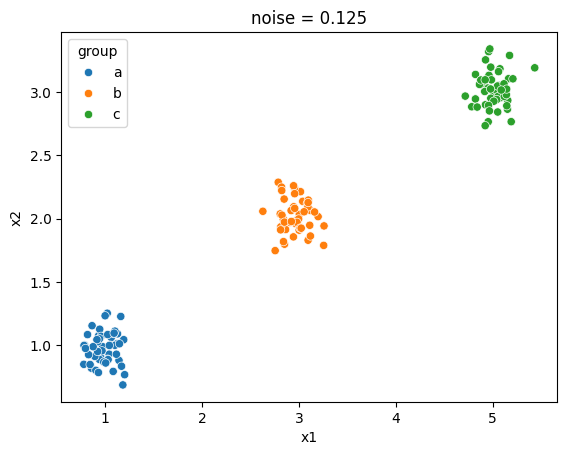

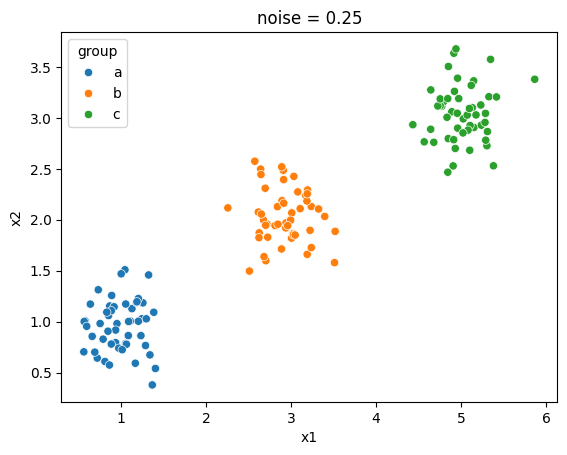

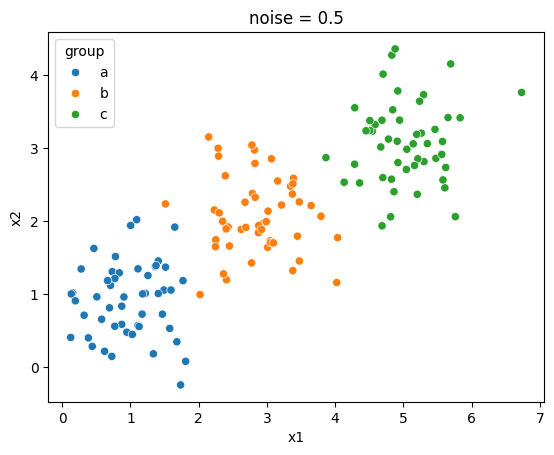

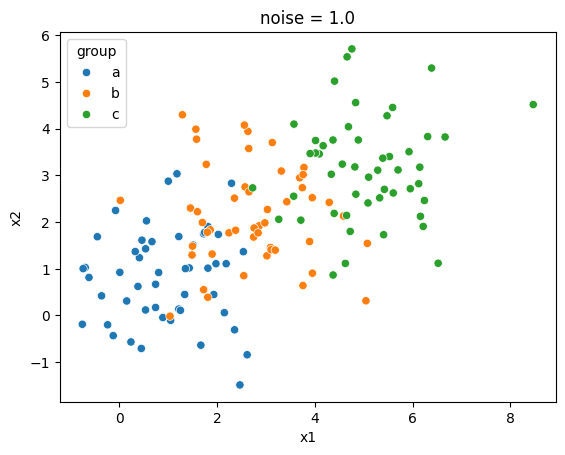

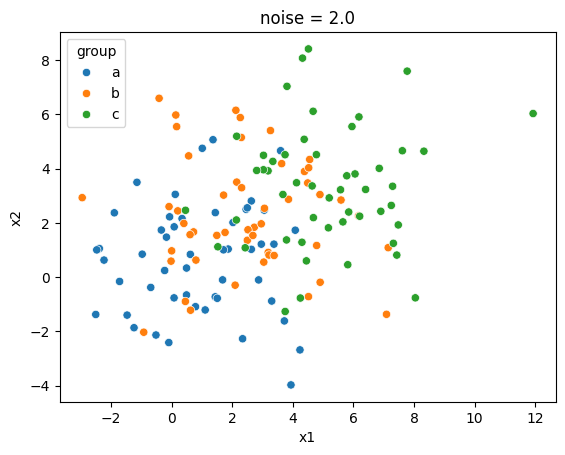

In [3]:
#2
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group").set(title="noise = 0.125")
plt.show()    #0.125

sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group").set(title="noise = 0.25")
plt.show()    #0.25

sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group").set(title="noise = 0.5")
plt.show()    #0.5

sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group").set(title="noise = 1.0")
plt.show()    #1.0

sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group").set(title="noise = 2.0")
plt.show()    #2.0

#As noise increases, the colors get less visually distinctive. When the noise in 0.125,
#the clusters are tight and distinctive, but at noise = 2.0 they are scattered all over.

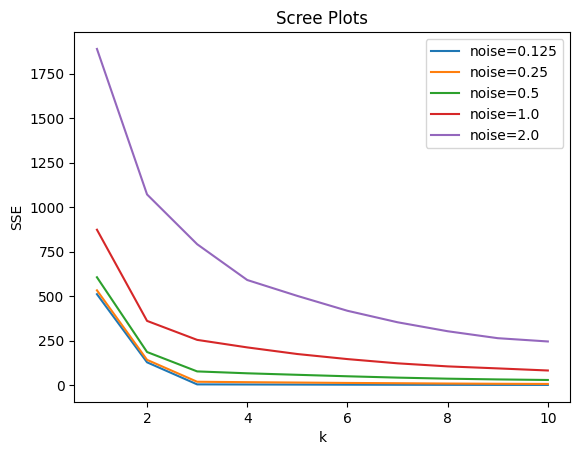

In [4]:
#3
from sklearn.cluster import KMeans
ks = np.arange(1, 11)

X = df0_125[["x1", "x2"]]
SSE0_125 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

X = df0_25[["x1", "x2"]]
SSE0_25 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

X = df0_5[["x1", "x2"]]
SSE0_5 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

X = df1_0[["x1", "x2"]]
SSE1_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

X = df2_0[["x1", "x2"]]
SSE2_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE0_125, label="noise=0.125")
sns.lineplot(x=ks, y=SSE0_25, label="noise=0.25")
sns.lineplot(x=ks, y=SSE0_5, label="noise=0.5")
sns.lineplot(x=ks, y=SSE1_0, label="noise=1.0")
sns.lineplot(x=ks, y=SSE2_0, label="noise=2.0")

plt.title("Scree Plots")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

#As noise increases, SSE is higher at every k.
#At lower noise there is a clear "elbow" at k=3.
#There is basically no clear 'elbow' at noise=2.0 as it fades gradually.
#Therefore, with low noise you can pick k=3 for certain, but you cannot with hih noise.

In [5]:
#4
#SSE always decreases as k increases, so can't just choose the k with the lowest SSE.
#Instead, look for the k where adding another cluster stops helping very much.
#Here, there are 3 true groups, so SSE drops a lot up to k=3, but not much after.
#The "elbow" is at k=3. There is virtually no "elbow" at the higher groups because they overlap.

In [6]:
#Q2
from google.colab import files
uploaded = files.upload()

Saving SIPRI Military Expenditure Database.csv to SIPRI Military Expenditure Database.csv


In [7]:
#1
df = pd.read_csv("SIPRI Military Expenditure Database.csv")
df = df.loc[df["Year"] == 2020]
df = df.dropna()  #drops empty columns
df.info()
#pretty sure no more cleaning is required here

<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB


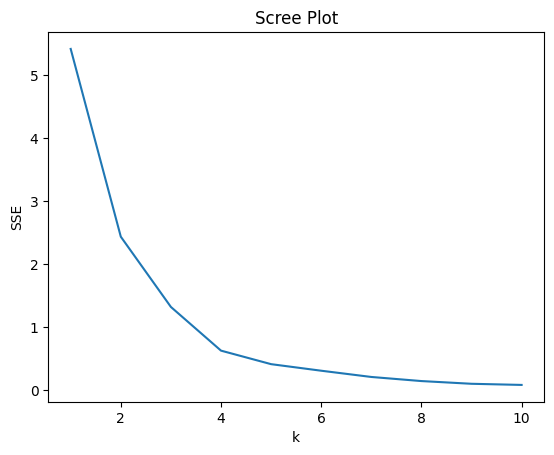

In [8]:
#2
# scaling data
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

# scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

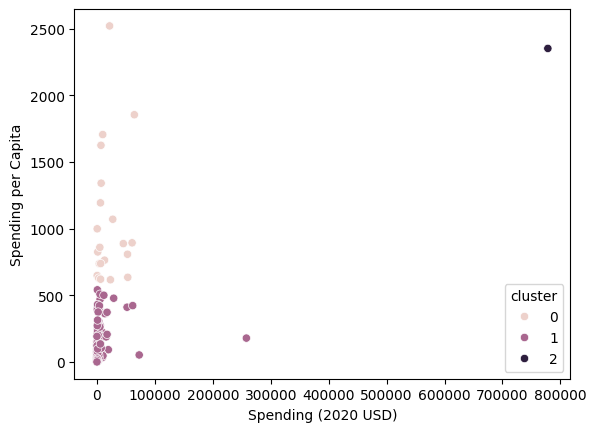

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      21.0  1046.433509  501.631845   616.854430   
1                     126.0   122.034996  140.041183     0.580129   
2                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         737.690186   859.880548  1193.598730  2520.398541  
1          18.505805    58.809109   188.249364   541.154778  
2        2351.631858  2351.631858  2351.631858  2351.631858

In [9]:
model = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model.fit(X)
df["cluster"] = model.predict(X)
# scater plot
sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster")
plt.show()
# groupby
df.groupby("cluster")[features].describe()

# The scree plot's elbow is around k=3, so I used 3 clusters.
# Cluster 2 is only the United States, with the highest total spending(by far) and very
# high spending per capita. Cluster 0 is 21 countries with high spending per
# capita but moderate total spending. The one outlier there is probably a very small, but wealthy country.
# Cluster 1 is the other 126 countries, with low spending per capita and low total spending. The clusters are mostly separated by spending
# per capita, and the US is an outlier in the whole data set because its total spending is so much larger than everyone else's.

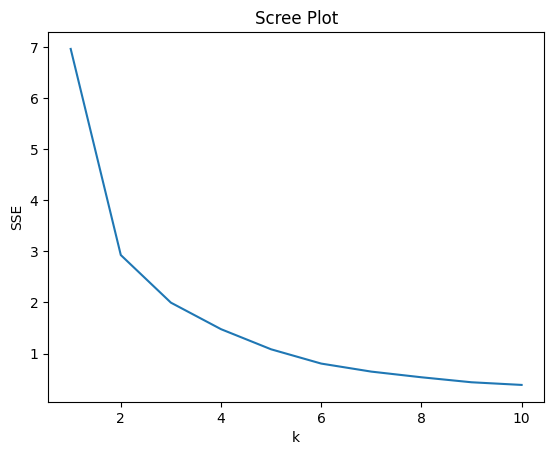

In [10]:
#3
# scale
features3 = ["Percent of Government Spending", "Percent of GDP"]
unscaled3 = df.loc[:, features3]
mins3 = unscaled3.min()
ranges3 = unscaled3.max() - mins3
X3 = (unscaled3 - mins3) / ranges3

# scree plot
ks = np.arange(1, 11)
SSE_3 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE_3).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

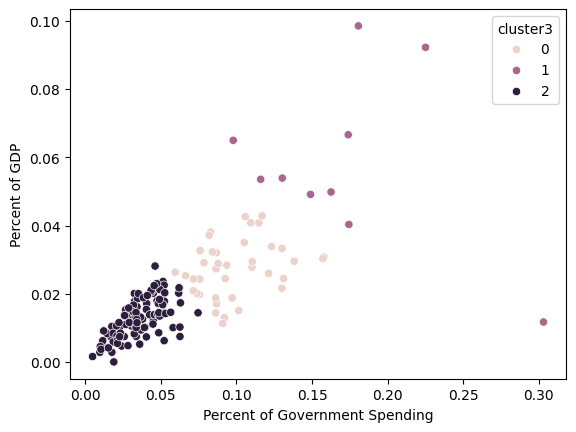

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  10.0  0.171289  0.058725  0.097882   
2                                  99.0  0.035777  0.014549  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                      
               std       min       25%       50%       75%       max  
cluster3                                                              
0         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

In [11]:
model3 = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model3.fit(X3)
df["cluster3"] = model3.predict(X3)
# scatter plot
sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster3")
plt.show()
# groupby
df.groupby("cluster3")[features3].describe()

In [12]:
# 3
# The scree plot bends around k=2 to 3, so I used 3 clusters.
# Cluster 2 is 99 countries that spend a low share of their budget and GDP on the military.
# Cluster 0 is 39 countries in the middle, and cluster 1 is 10 countries with the highest shares.
# The US is not an outlier here unlike Q2. Countries are grouped by what pecent
# of their budget and economy goes to the military, versus by how much they spend in total.
# Therefore, the clusters are low, medium, and high levels along one trend instead of one big outlier.

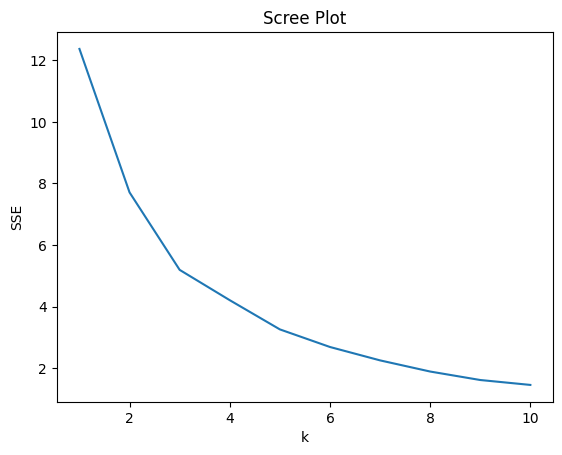

In [13]:
# 4
# scale
features4 = ["Spending (2020 USD)", "Spending per Capita",
             "Percent of Government Spending", "Percent of GDP"]
unscaled4 = df.loc[:, features4]
mins4 = unscaled4.min()
ranges4 = unscaled4.max() - mins4
X4 = (unscaled4 - mins4) / ranges4

# Scree plot
ks = np.arange(1, 11)
SSE4 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X4).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE4).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

In [14]:
model4 = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model4.fit(X4)
df["cluster4"] = model4.predict(X4)

df.groupby("cluster4")[features4].describe()

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                       31.0    8786.086602   17901.909108   162.373364   
2                        6.0  147964.582042  309635.189564  6095.708713   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1          467.787851   1404.787234   7739.166193   72937.064048   
2         7700.424616  15897.570598  53872.942442  778397.200000   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster4                                   ...                                  
0                      111.0   196.926833  ...                       0.050505   
1                       31.0   212.689100  ...                       0.134663   
2                        6.0  1875.150751  ...                       0.164503   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster4                                                                    
0         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
1         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
2         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   

                                        
               50%       75%       max  
cluster4                                
0         0.013589  0.017769  0.028132  
1         0.032024  0.040531  0.066600  
2         0.059257  0.085398  0.098470  

[3 rows x 32 columns]

In [15]:
df.loc[df["Country"] == "United States of America", ["Country", "cluster4"]]
#4
# The Scree plot only has a small bend around k=3, so the elbow is not as clear as it was previously.
# The US is in cluster 2 with 5 other countries that are high on spending, spending per capita, and percent of GDP.
# In part 2 the US was alone, so here it is grouped with other countries that spend a lot per person and share of GDP.

,Country,cluster4
5540,United States of America,2


In [16]:
# 5
# Yes. It showed that the US is an outlier in total spending (part 2) and that countries
# fall into low, medium and high spending (part 3). But there are a few limits:
# k is not always clear and one outlier can take over a cluster.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [Claude Opus]

### *Prompts used

1. Hey claude I want you to review my homework project (phase 1) and provide a numbered list of simple changes that I can make to enhance my learning and become a better coder?

### *AI-proposed changes


1. Write helper functions for repeated code. The scree loop appears 8 times and the max min scaling 3 times. A scree(X) function and a minmax(df, cols) function would cut most of your code and prevent copy paste mistakes.
2. Give Q2.1 a real answer instead of “pretty sure.” Use df.describe() to point out that index and Year are useless for clustering and that Spending (2020 USD) is extremely skewed (the US is about 60 times the mean). 3.Also fix the comment: dropna() drops rows, not columns.
3. Check your guesses with code. In Q2.2 you guessed the cluster 0 outlier is “probably a very small, but wealthy country.” Sorting that cluster by Spending per Capita shows it is Israel. Verifying beats guessing.
4. Log transform the spending variables before clustering in Q2.2. Spending (2020 USD) is so skewed that the US alone stretches the whole scale, so max min scaling squeezes the other 147 countries into a tiny range. Apply np.log() to both spending columns before scaling, rerun the scree plot and k means, and compare. This shows how preprocessing choices change what k means finds.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I will accept because the code is repetive and I can make it cleaner. It also will help elminate potential silly mistakes |
| 2 | Accept | I will accept because my "pretty sure" was not a good enough answer. Also, dropna() drops rows, not columns so that markdown was an error. Next, I will use df.describe() to figure out what is useful for clustering and what skews the data. |
| 3 | Accept | I will accept because I just guessed earlier what the outliers might be which is lazy. Turns out that Israel is that outlier (so I was very close!), and I should have confirmed with code. |
| 4 | Accept | I will accept because the US was skewing the data, and was its own cluster. I am using np.log() on both soending columns to make the clusters more balanced and to scale. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [18]:
#1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

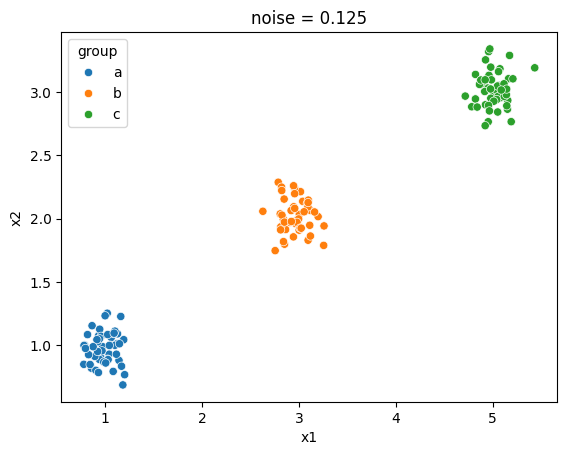

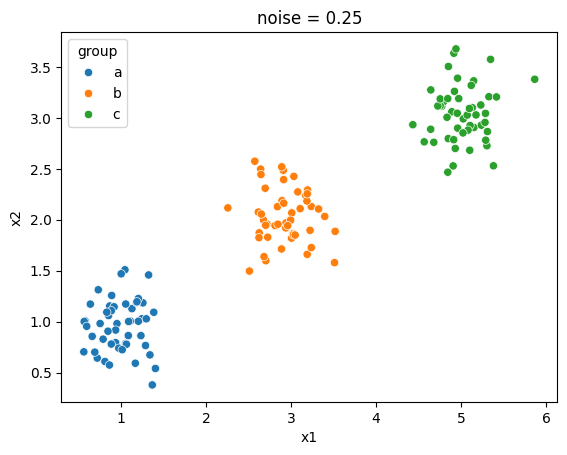

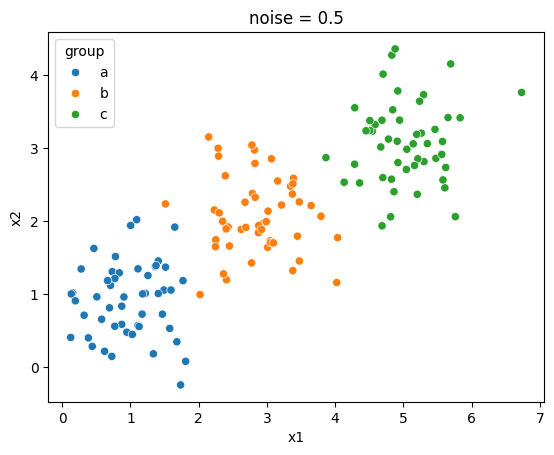

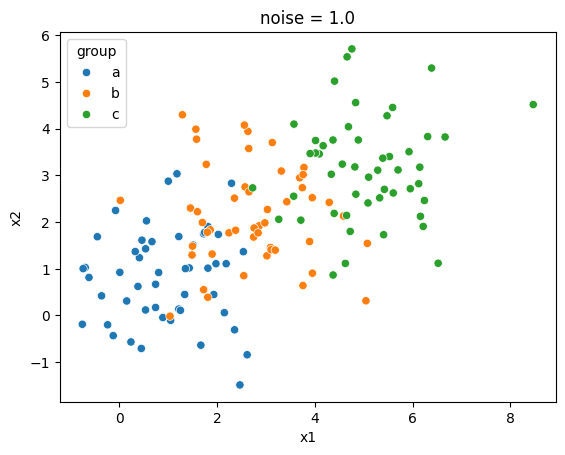

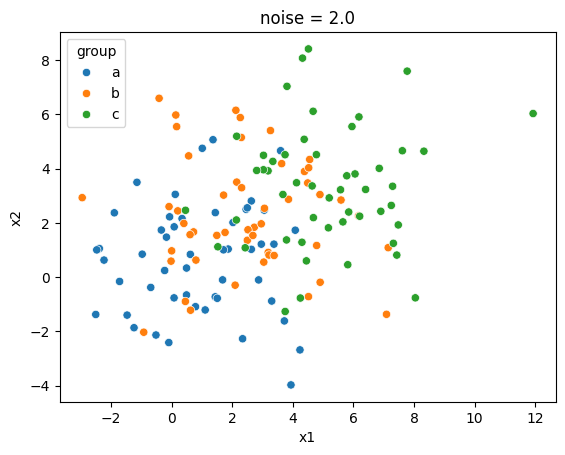

In [19]:
#2
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group").set(title="noise = 0.125")
plt.show()    #0.125

sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group").set(title="noise = 0.25")
plt.show()    #0.25

sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group").set(title="noise = 0.5")
plt.show()    #0.5

sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group").set(title="noise = 1.0")
plt.show()    #1.0

sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group").set(title="noise = 2.0")
plt.show()    #2.0

#As noise increases, the colors get less visually distinctive. When the noise in 0.125,
#the clusters are tight and distinctive, but at noise = 2.0 they are scattered all over.

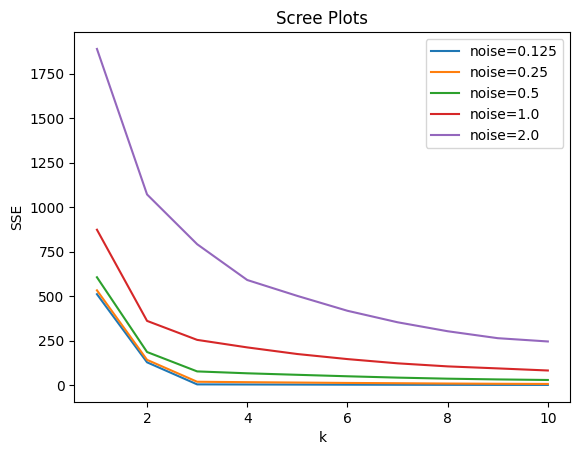

In [20]:
#3
from sklearn.cluster import KMeans
ks = np.arange(1, 11)

# Change 1: helper functions replace the repeated scree loop and max min scaling
def scree(X):
    return [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

def minmax(df, cols):
    unscaled = df.loc[:, cols]
    mins = unscaled.min()
    ranges = unscaled.max() - mins
    return (unscaled - mins) / ranges

SSE0_125 = scree(df0_125[["x1", "x2"]])
SSE0_25 = scree(df0_25[["x1", "x2"]])
SSE0_5 = scree(df0_5[["x1", "x2"]])
SSE1_0 = scree(df1_0[["x1", "x2"]])
SSE2_0 = scree(df2_0[["x1", "x2"]])

sns.lineplot(x=ks, y=SSE0_125, label="noise=0.125")
sns.lineplot(x=ks, y=SSE0_25, label="noise=0.25")
sns.lineplot(x=ks, y=SSE0_5, label="noise=0.5")
sns.lineplot(x=ks, y=SSE1_0, label="noise=1.0")
sns.lineplot(x=ks, y=SSE2_0, label="noise=2.0")

plt.title("Scree Plots")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

#As noise increases, SSE is higher at every k.
#At lower noise there is a clear "elbow" at k=3.
#There is basically no clear 'elbow' at noise=2.0 as it fades gradually.
#Therefore, with low noise you can pick k=3 for certain, but you cannot with hih noise.

In [21]:
#4
# SSE always decreases as k increases, so can't just choose the k with the lowest SSE.
# Instead, look for the k where adding another cluster stops helping very much.
# Here, there are 3 true groups, so SSE drops a lot up to k=3, but not much after.
# The "elbow" is at k=3. There is virtually no "elbow" at the higher groups because they overlap.

In [22]:
#Q2
from google.colab import files
uploaded = files.upload()

Saving SIPRI Military Expenditure Database.csv to SIPRI Military Expenditure Database (1).csv


In [23]:
#1
df = pd.read_csv("SIPRI Military Expenditure Database.csv")
df = df.loc[df["Year"] == 2020]
df = df.dropna()  #drops rows with any missing values (Not Columns!!!)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB


In [25]:
print("Unique years:", df["Year"].nunique())
print("Max / mean total spending:",
      round(df["Spending (2020 USD)"].max() / df["Spending (2020 USD)"].mean(), 1))
df.describe()
# Change 2: 148 countries remain and all spending variables are numeric, but two things
# need attention. "index" is just a leftover row number and "Year" is now always 2020,
# so neither should be used for clustering. "Spending (2020 USD)" is extremely skewed:
# the US is about 59 times the mean, so with max min scaling it sets the whole range
# and squeezes the other countries close to zero.

Unique years: 1
Max / mean total spending: 59.2


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


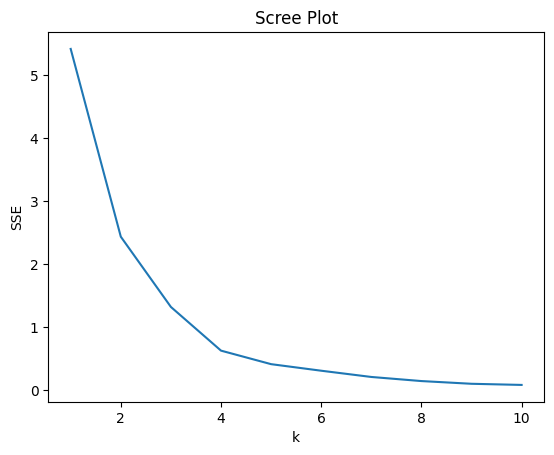

In [26]:
#2
# scaling data
features = ["Spending (2020 USD)", "Spending per Capita"]
X = minmax(df, features)
X.agg(["min", "max"])

# scree plot
SSE = scree(X)
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

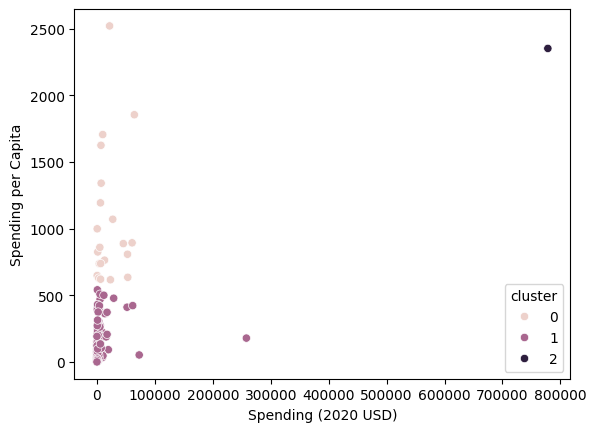

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      21.0  1046.433509  501.631845   616.854430   
1                     126.0   122.034996  140.041183     0.580129   
2                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         737.690186   859.880548  1193.598730  2520.398541  
1          18.505805    58.809109   188.249364   541.154778  
2        2351.631858  2351.631858  2351.631858  2351.631858

In [31]:
model = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model.fit(X)
df["cluster"] = model.predict(X)
# scater plot
sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster")
plt.show()
# groupby
df.groupby("cluster")[features].describe()
# The scree plot's elbow is around k=3, so I used 3 clusters.

In [30]:
df.loc[df["cluster"] == 0, ["Country"] + features].sort_values(
    "Spending per Capita", ascending=False).head()
# Cluster 2 is only the United States, with the highest total spending(by far) and very
# high spending per capita. Cluster 0 is 21 countries with high spending per
# capita but moderate total spending. Sorting cluster 0 shows the outlier is Israel, the highest
# per capita spender in the data, followed by Saudi Arabia, Singapore, and Kuwait.
# Cluster 1 is the other 126 countries, with low spending per capita and low total spending. The clusters are mostly separated by spending
# per capita, and the US is an outlier in the whole data set because its total spending is so much larger than everyone else's.

,Country,Spending (2020 USD),Spending per Capita
2582,Israel,21816.569767,2520.398541
4486,Saudi Arabia,64558.400000,1854.380422
4656,Singapore,9978.571429,1705.738706
2922,Kuwait,6941.042345,1625.156250
4010,Norway,7269.880030,1341.058851


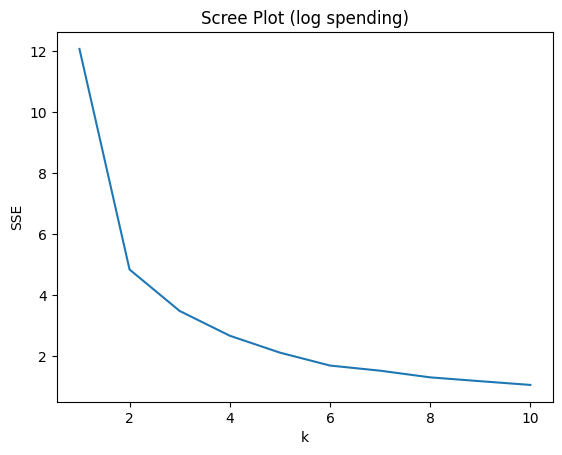

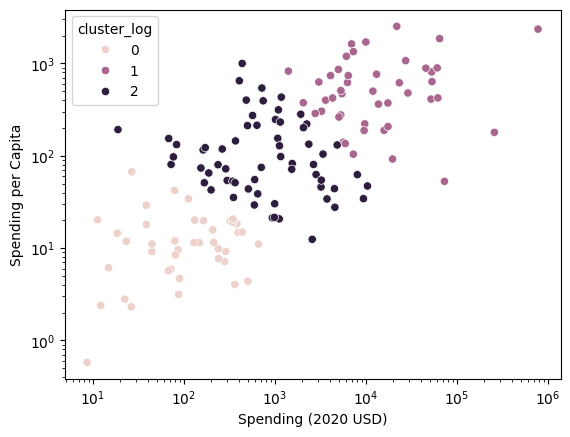

cluster_log
2    62
1    45
0    41
Name: count, dtype: int64
US cluster size: 45


Spending (2020 USD)                                            \
                          count          mean            std          min   
cluster_log                                                                 
0                          41.0    167.505999     159.830080     8.622460   
1                          45.0  40926.610075  119623.341226  1404.787234   
2                          62.0   1583.700900    2138.521992    18.814132   

                                                                    \
                     25%          50%           75%            max   
cluster_log                                                          
0              38.618837    89.409368    279.576955     659.313034   
1            5301.379232  9708.277440  27300.894701  778397.200000   
2             345.517698   730.080930   2022.284878   10394.502555   

            Spending per Capita                                     \
                          count        mean         std        min   
cluster_log                                                          
0                          41.0   13.957338   12.162077   0.580129   
1                          45.0  667.589998  578.303553  52.852792   
2                          62.0  146.602328  170.305809  12.457154   

                                                              
                    25%         50%         75%          max  
cluster_log                                                   
0              6.125369   11.417058   18.297119    67.083417  
1            276.532992  478.339168  825.374403  2520.398541  
2             48.057252   80.521476  182.634762   998.966186

In [32]:
log_df = np.log(df[features])  # all values are positive, so log is okay
X_log = minmax(log_df, features)

SSE_log = scree(X_log)
sns.lineplot(x=ks, y=SSE_log).set(title="Scree Plot (log spending)", xlabel="k", ylabel="SSE")
plt.show()

model_log = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
df["cluster_log"] = model_log.fit_predict(X_log)
sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster_log")
plt.xscale("log")
plt.yscale("log")
plt.show()

print(df["cluster_log"].value_counts())
us_cluster = df.loc[df["Country"] == "United States of America", "cluster_log"].item()
print("US cluster size:", (df["cluster_log"] == us_cluster).sum())
df.groupby("cluster_log")[features].describe()

# Change 4: With log spending the clusters are much more balanced (41, 45, and 62 countries
# instead of 21, 126, and 1). The US is no longer alone; it is grouped with 44 other large
# spenders like China, Russia, the UK, and Israel. The original result was driven by the US
# stretching the scale rather than a real pattern among most countries.

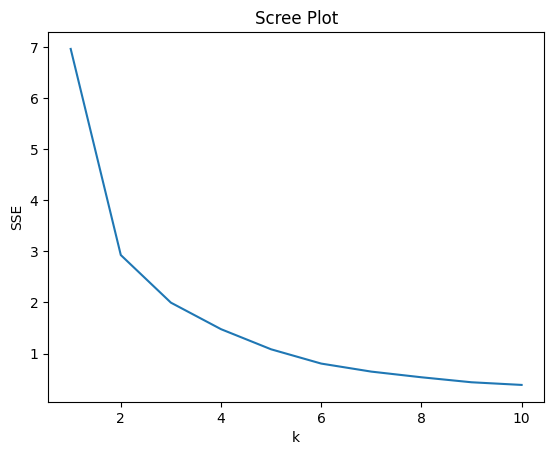

In [33]:
# scale
features3 = ["Percent of Government Spending", "Percent of GDP"]
X3 = minmax(df, features3)

# scree plot
SSE_3 = scree(X3)
sns.lineplot(x=ks, y=SSE_3).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

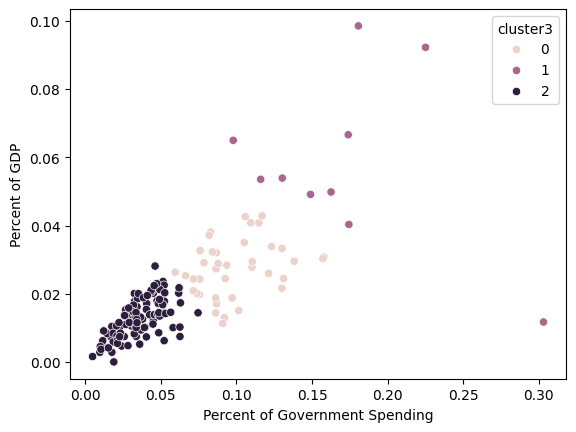

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  10.0  0.171289  0.058725  0.097882   
2                                  99.0  0.035777  0.014549  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                      
               std       min       25%       50%       75%       max  
cluster3                                                              
0         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

In [34]:
model3 = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model3.fit(X3)
df["cluster3"] = model3.predict(X3)
# scatter plot
sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster3")
plt.show()
# groupby
df.groupby("cluster3")[features3].describe()

In [35]:
# 3
# The scree plot bends around k=2 to 3, so I used 3 clusters.
# Cluster 2 is 99 countries that spend a low share of their budget and GDP on the military.
# Cluster 0 is 39 countries in the middle, and cluster 1 is 10 countries with the highest shares.
# The US is not an outlier here unlike Q2. Countries are grouped by what pecent
# of their budget and economy goes to the military, versus by how much they spend in total.
# Therefore, the clusters are low, medium, and high levels along one trend instead of one big outlier.

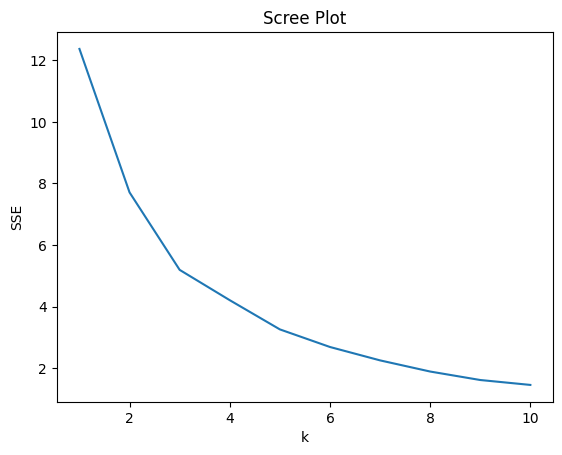

In [36]:
# 4
# scale
features4 = ["Spending (2020 USD)", "Spending per Capita",
             "Percent of Government Spending", "Percent of GDP"]
X4 = minmax(df, features4)

# Scree plot
SSE4 = scree(X4)
sns.lineplot(x=ks, y=SSE4).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

In [37]:
model4 = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model4.fit(X4)
df["cluster4"] = model4.predict(X4)

df.groupby("cluster4")[features4].describe()

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                       31.0    8786.086602   17901.909108   162.373364   
2                        6.0  147964.582042  309635.189564  6095.708713   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1          467.787851   1404.787234   7739.166193   72937.064048   
2         7700.424616  15897.570598  53872.942442  778397.200000   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster4                                   ...                                  
0                      111.0   196.926833  ...                       0.050505   
1                       31.0   212.689100  ...                       0.134663   
2                        6.0  1875.150751  ...                       0.164503   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster4                                                                    
0         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
1         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
2         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   

                                        
               50%       75%       max  
cluster4                                
0         0.013589  0.017769  0.028132  
1         0.032024  0.040531  0.066600  
2         0.059257  0.085398  0.098470  

[3 rows x 32 columns]

In [38]:
df.loc[df["Country"] == "United States of America", ["Country", "cluster4"]]
#4
# The Scree plot only has a small bend around k=3, so the elbow is not as clear as it was previously.
# The US is in cluster 2 with 5 other countries that are high on spending, spending per capita, and percent of GDP.
# In part 2 the US was alone, so here it is grouped with other countries that spend a lot per person and share of GDP.

,Country,cluster4
5540,United States of America,2


In [39]:
# 5
# Yes. It showed that the US is an outlier in total spending (part 2) and that countries
# fall into low, medium and high spending (part 3). But there are a few limits:
# k is not always clear and one outlier can take over a cluster.
# NEW UPDATE: the log solution from Claude showed that the US as an outlier can be eliminated and the groups became more balanced.

### *Reflection on AI assistance
In your own words without generative AI.

First of all, I really enjoyed this assignment. Politics is a hobby for me and I am concerned like most other Americans about our National Debt and how much we spend on things like the Military. In terms of the assignment, it was super cool to be able to translate the data into graphs that maybe it easier to understand. Claude was helpful in phase 2 by making my code less repetive because I just copied the slide format over and over in Q1, but Claude added a helper loop for me, which I hope to implement on future assignments. Second, I messed up the graph by thinking that "index" and "year" were useful, and Claude help me realize they were not. It also suggested a log format for the countries' spending; this was primarily because the US was such a large outlier. I'm still not sure if this was the correct approach or not for this assignment. One lingering question I have on this assignment is when to use an elbow that looks unclear. For example, I chose n=3 at a few points because it looked relatively close. I'm not sure how to approach that in the future. In conclusion, this was a helpful and interesting assignment.